# Analysis of a multi-task model

A trained TSsBN model's scales form an importance matrix `I = sigmoid(gamma)` of shape
`[tasks, filters]`. `tssnorm.get_importance(model)` returns it. The analysis of Section 5 reads
everything from `I`, so it needs no data and no extra forward passes.

`tssnorm.mtl` holds the analysis as functions of `I`. This notebook runs them on the NYUv2 model
of Table 2: DeepLabV3 with ResNet-50, and three tasks.

Git does not track the matrix. To analyse your own model, save its matrix as
[`mtl/README.md`](../README.md) shows, and point `MATRIX` below at it.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from tssnorm.mtl import capacity, capacity_decomposition, task_similarity, specialized_filters

# A [tasks, filters] importance matrix from a trained model: I = get_importance(model).
MATRIX = Path("models/nyuv2_tssbn.npy")
if not MATRIX.exists():
    raise FileNotFoundError(
        f"{MATRIX} not found. Save a trained model's importance matrix with "
        "numpy.save(path, get_importance(model).cpu().numpy()) and point MATRIX at it. "
        "See mtl/README.md."
    )

I = np.load(MATRIX)
TASKS = ["segmentation", "depth", "normals"]
print(f"importance matrix {I.shape} = [tasks, filters]  tasks={TASKS}")

importance matrix (3, 26560) = [tasks, filters]  tasks=['segmentation', 'depth', 'normals']


## Capacity (5.1, Figure 3)

`capacity(I)` is each task's capacity, `C_t = mean_i I[t, i]`. `capacity_decomposition(I)` splits
it into a shared part and an independent part. The shared part is the projection of the task's
importance vector onto the span of the other tasks. The independent part is the rest. The two
are orthogonal, so `shared^2 + independent^2 = C_t^2`. That is why the plot stacks squared parts.
Most capacity is shared, and no task dominates.

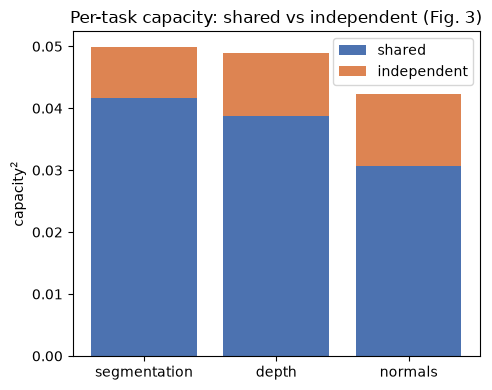

  segmentation  capacity 0.223   shared 83%
  depth         capacity 0.221   shared 79%
  normals       capacity 0.206   shared 72%


In [2]:
C = capacity(I)
shared, indep = capacity_decomposition(I)

fig, ax = plt.subplots(figsize=(5, 4))
x = np.arange(len(TASKS))
ax.bar(x, shared**2, label="shared", color="#4C72B0")
ax.bar(x, indep**2, bottom=shared**2, label="independent", color="#DD8452")
ax.set_xticks(x); ax.set_xticklabels(TASKS)
ax.set_ylabel("capacity$^2$"); ax.set_title("Per-task capacity: shared vs independent (Fig. 3)")
ax.legend(); fig.tight_layout(); plt.show()

# the shared fraction of capacity is likewise a ratio of squares
for t, c, s in zip(TASKS, C, shared):
    print(f"  {t:13s} capacity {c:.3f}   shared {s**2 / c**2:.0%}")

## Task relationships (5.2)

`task_similarity(I)` is the cosine similarity between the tasks' importance vectors. It is 1 for
identical filter use and 0 for no filters in common. With many tasks, `task_clusters(I)` clusters
them, as in Table 5. With three tasks, the matrix itself is enough.

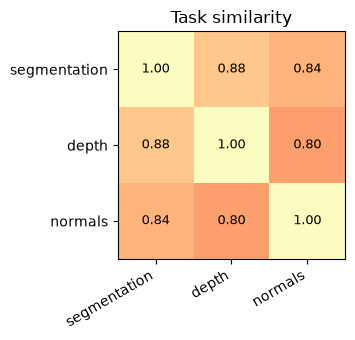

In [3]:
S = task_similarity(I)
fig, ax = plt.subplots(figsize=(4, 3.5))
im = ax.imshow(S, cmap="magma", vmin=0, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(TASKS, rotation=30, ha="right")
ax.set_yticks(range(3)); ax.set_yticklabels(TASKS)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{S[i,j]:.2f}", ha="center", va="center",
                color="white" if S[i,j] < 0.6 else "black", fontsize=9)
ax.set_title("Task similarity"); fig.tight_layout(); plt.show()

## Filter specialisation (5.3)

`specialized_filters(I, tau)` marks a filter as specialised for a task when that task holds more
than `tau` of the filter's total importance. Most filters are shared. A minority specialise to
one task.

In [4]:
spec = specialized_filters(I, tau=0.5)
print(f"{spec.any(axis=0).mean():.1%} of filters are specialized to a single task (tau=0.5)")
for t, n in zip(TASKS, spec.sum(axis=1)):
    print(f"  {t:13s} {n:5d} specialized filters")

21.5% of filters are specialized to a single task (tau=0.5)
  segmentation   1878 specialized filters
  depth          2138 specialized filters
  normals        1700 specialized filters


## Many tasks

Clustering (5.2, Table 5) and the stability of task similarity across runs
(`similarity_stability`) need many tasks. To run them, save the importance matrix of a model with
many tasks, such as 40-task CelebA, to `models/`.